<a href="https://colab.research.google.com/github/akshat337/Local-repo/blob/main/Activity_1_of_Naive_Bayes_Gaussian_Naive_Bayes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Rows always classes
# Columns always Features

In [ ]:
# 1. Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
import kagglehub
import pandas as pd
import glob
import os

# Download dataset from Kaggle
path = kagglehub.dataset_download("mshanasl/playsheet-ds")

print("Dataset downloaded at:", path)

# Find CSV files
csv_files = glob.glob(os.path.join(path, "*.csv"))

# Load the first CSV file
df = pd.read_csv(csv_files[0])

# Display dataset
print(df.head())
print("\nColumns:", df.columns.tolist())
print("\nDataset Shape:", df.shape)

Using Colab cache for faster access to the 'playsheet-ds' dataset.
Dataset downloaded at: /kaggle/input/playsheet-ds
    Outlook  Temp Humidity Windy Play
0     Rainy   Hot     High     f   no
1     Rainy   Hot     High     t   no
2  Overcast   Hot     High     f  yes
3     Sunny  Mild     High     f  yes
4     Sunny  Cool   Normal     f  yes

Columns: ['Outlook', 'Temp', 'Humidity', 'Windy', 'Play']

Dataset Shape: (14, 5)


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset overview
print("Dataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe(include='all'))

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Outlook   14 non-null     object
 1   Temp      14 non-null     object
 2   Humidity  14 non-null     object
 3   Windy     14 non-null     object
 4   Play      14 non-null     object
dtypes: object(5)
memory usage: 692.0+ bytes
None

Statistical Summary:
       Outlook  Temp Humidity Windy Play
count       14    14       14    14   14
unique       3     3        2     2    2
top      Rainy  Mild     High     f  yes
freq         5     6        7     8    9

Missing Values:
Outlook     0
Temp        0
Humidity    0
Windy       0
Play        0
dtype: int64

Duplicate Records: 0


In [ ]:
# 2. Select and clean the required columns
data = df[['Outlook', 'Play']].copy()
data.dropna(inplace=True)
data['Outlook'] = data['Outlook'].str.strip().str.lower()
data['Play'] = data['Play'].str.strip().str.lower()

In [ ]:
# 3. Separate input and target
X = data[['Outlook']]
y = data['Play']

# Convert categorical input into numerical binary columns
weather_encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
X_encoded = weather_encoder.fit_transform(X)

# Encode target labels
play_encoder = LabelEncoder()
y_encoded = play_encoder.fit_transform(y)

print("Weather Encoding:")
print(pd.DataFrame(
    X_encoded,
    columns=weather_encoder.get_feature_names_out(['Outlook'])
).head())

print("\nPlay Encoding:")
print(dict(zip(
    play_encoder.classes_,
    play_encoder.transform(play_encoder.classes_)
)))

Weather Encoding:
   Outlook_overcast  Outlook_rainy  Outlook_sunny
0               0.0            1.0            0.0
1               0.0            1.0            0.0
2               1.0            0.0            0.0
3               0.0            0.0            1.0
4               0.0            0.0            1.0

Play Encoding:
{'no': np.int64(0), 'yes': np.int64(1)}


In [ ]:
# 4. Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y_encoded,
    test_size=0.3,
    random_state=42,
    stratify=y_encoded
)

print("\nTraining Records:", len(X_train))
print("Testing Records:", len(X_test))


Training Records: 9
Testing Records: 5


In [ ]:
# 5. Create and train Gaussian Naive Bayes model
model = GaussianNB()
model.fit(X_train, y_train)

GaussianNB()

In [ ]:
# 6. Make predictions
y_pred = model.predict(X_test)

print("\nActual Values:", y_test)
print("Predicted Values:", y_pred)


Actual Values: [1 1 0 1 0]
Predicted Values: [1 1 0 0 0]


In [ ]:
# 7. Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("\nModel Accuracy:", accuracy * 100, "%")


Model Accuracy: 80.0 %


In [ ]:
# 8. Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=play_encoder.classes_,
    zero_division=0
))


Classification Report:
              precision    recall  f1-score   support

          no       0.67      1.00      0.80         2
         yes       1.00      0.67      0.80         3

    accuracy                           0.80         5
   macro avg       0.83      0.83      0.80         5
weighted avg       0.87      0.80      0.80         5



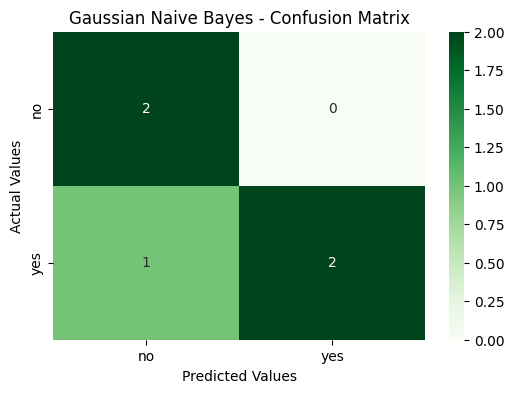

In [ ]:
# 9. Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=play_encoder.classes_,
    yticklabels=play_encoder.classes_
)

plt.title("Gaussian Naive Bayes - Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

In [ ]:
# 10. Predict for new weather conditions
new_weather = pd.DataFrame({
    'Outlook': ['sunny', 'rainy', 'overcast']
})

new_encoded = weather_encoder.transform(new_weather)
predictions = model.predict(new_encoded)

print("\nWeather-Based Play Prediction:\n")
for weather, prediction in zip(new_weather['Outlook'], predictions):
    result = play_encoder.inverse_transform([prediction])[0]
    print(f"{weather.upper()} -> Play: {result.upper()}")


Weather-Based Play Prediction:

SUNNY -> Play: NO
RAINY -> Play: NO
OVERCAST -> Play: YES


In [ ]:
# 11. Display prediction probabilities
probabilities = model.predict_proba(new_encoded)

for weather, probs in zip(new_weather['Outlook'], probabilities):
    print(f"\nWeather: {weather.upper()}")
    for label, probability in zip(play_encoder.classes_, probs):
        print(f"Play = {label}: {probability * 100:.2f}%")


Weather: SUNNY
Play = no: 99.99%
Play = yes: 0.01%

Weather: RAINY
Play = no: 100.00%
Play = yes: 0.00%

Weather: OVERCAST
Play = no: 0.00%
Play = yes: 100.00%


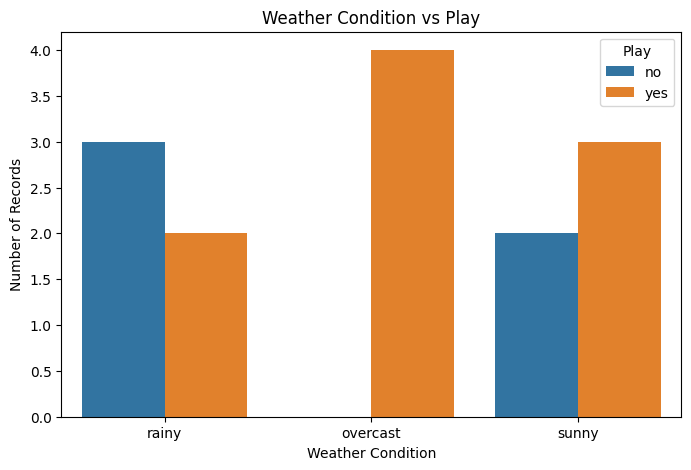

In [ ]:
# 12. Graph: Weather vs Play
plt.figure(figsize=(8, 5))
sns.countplot(
    data=data,
    x='Outlook',
    hue='Play'
)

plt.title("Weather Condition vs Play")
plt.xlabel("Weather Condition")
plt.ylabel("Number of Records")
plt.show()

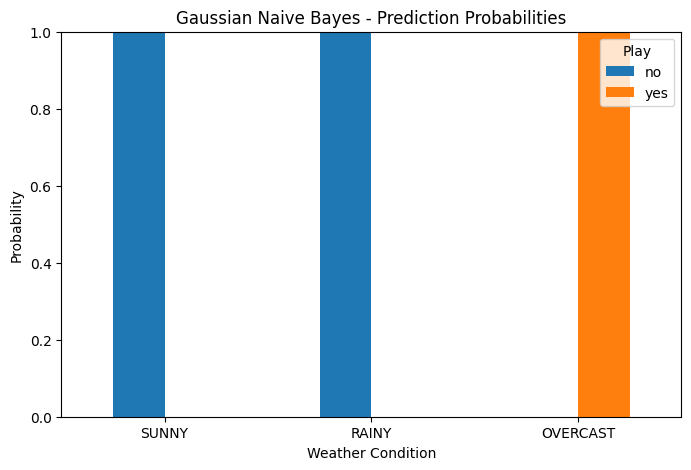

In [ ]:
# 13. Graph: Prediction Probabilities
probability_df = pd.DataFrame(
    probabilities,
    columns=play_encoder.classes_,
    index=new_weather['Outlook'].str.upper()
)

probability_df.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title("Gaussian Naive Bayes - Prediction Probabilities")
plt.xlabel("Weather Condition")
plt.ylabel("Probability")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Play")
plt.show()

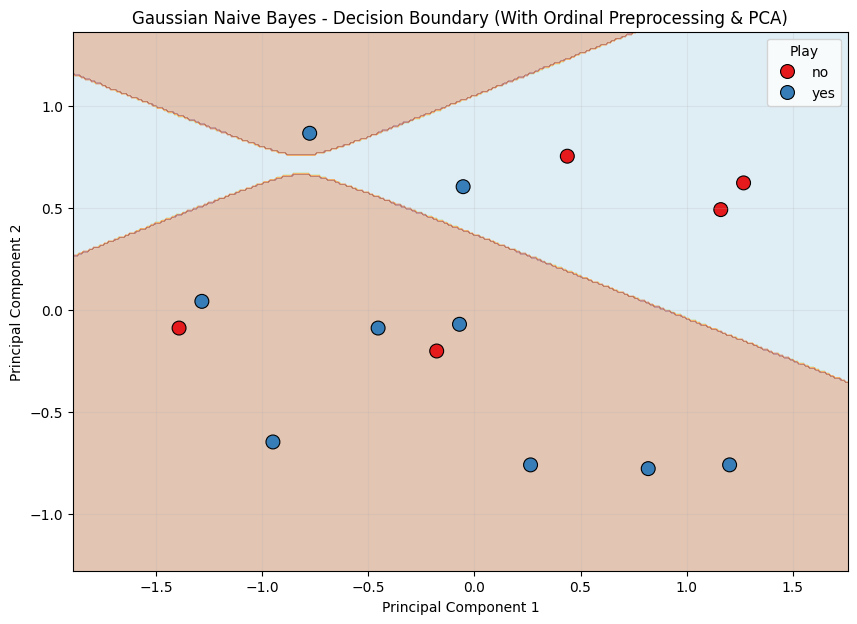

In [ ]:
# DECISION BOUNDARY VISUALIZATION - GAUSSIAN NAIVE BAYES (WITH ORDINAL MAPPINGS)

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.naive_bayes import GaussianNB

# 1. Prepare the dataset
data = df[['Outlook', 'Temp', 'Humidity', 'Windy', 'Play']].dropna().copy()

# Standardize text
for col in ['Outlook', 'Temp', 'Humidity', 'Windy', 'Play']:
    data[col] = data[col].astype(str).str.strip().str.lower()

# 2. Custom Encoding: Ordinal for ordered categories, One-Hot for nominal categories
# Map Temp: cool -> 0, mild -> 1, hot -> 2
temp_map = {'cool': 0, 'mild': 1, 'hot': 2}
data['Temp_encoded'] = data['Temp'].map(temp_map)

# Map Humidity: normal -> 0, high -> 1
humidity_map = {'normal': 0, 'high': 1}
data['Humidity_encoded'] = data['Humidity'].map(humidity_map)

# Map Windy: f -> 0, t -> 1
windy_map = {'f': 0, 't': 1}
data['Windy_encoded'] = data['Windy'].map(windy_map)

# One-Hot Encode nominal 'Outlook'
outlook_encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
outlook_encoded = outlook_encoder.fit_transform(data[['Outlook']])

# Combine processed features
features_combined = np.column_stack((
    outlook_encoded,
    data['Temp_encoded'].values,
    data['Humidity_encoded'].values,
    data['Windy_encoded'].values
))

# Encode target
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(data['Play'])

# 3. Reduce features to 2 dimensions using PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(features_combined)

# 4. Train Gaussian Naive Bayes
model = GaussianNB()
model.fit(X_pca, y_encoded)

# 5. Create a mesh grid
x_min, x_max = X_pca[:, 0].min() - 0.5, X_pca[:, 0].max() + 0.5
y_min, y_max = X_pca[:, 1].min() - 0.5, X_pca[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.01),
    np.arange(y_min, y_max, 0.01)
)

# 6. Predict each point in the grid
Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# 7. Plot decision regions and data points
plt.figure(figsize=(10, 7))

plt.contourf(
    xx, yy, Z,
    alpha=0.35,
    cmap=plt.cm.Paired
)

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=label_encoder.inverse_transform(y_encoded),
    palette='Set1',
    s=100,
    edgecolor='black'
)

plt.title('Gaussian Naive Bayes - Decision Boundary (With Ordinal Preprocessing & PCA)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Play')
plt.grid(alpha=0.2)
plt.show()